In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("breast_cancer_data.csv")

In [3]:
df.shape

(569, 33)

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
df.drop("id", axis=1, inplace=True)
df.drop(df.columns[-1], axis=1, inplace=True)

df = df.sample(frac=1, random_state=41).reset_index(drop=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [6]:
df.isna().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [7]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0,12.58,18.40,79.83,489.0,0.08393,0.04216,0.00186,0.002924,0.1697,...,13.50,23.08,85.56,564.1,0.10380,0.06624,0.005579,0.008772,0.2505,0.06431
1,0,14.76,14.74,94.87,668.7,0.08875,0.07780,0.04608,0.035280,0.1521,...,17.27,17.93,114.20,880.8,0.12200,0.20090,0.215100,0.125100,0.3109,0.08187
2,0,14.64,15.24,95.77,651.9,0.11320,0.13390,0.09966,0.070640,0.2116,...,16.34,18.24,109.40,803.6,0.12770,0.30890,0.260400,0.139700,0.3151,0.08473
3,0,12.65,18.17,82.69,485.6,0.10760,0.13340,0.08017,0.050740,0.1641,...,14.38,22.15,95.29,633.7,0.15330,0.38420,0.358200,0.140700,0.3230,0.10330
4,0,12.43,17.00,78.60,477.3,0.07557,0.03454,0.01342,0.016990,0.1472,...,12.90,20.21,81.76,515.9,0.08409,0.04712,0.022370,0.028320,0.1901,0.05932


In [8]:
# Train Test split 80/20
train_size = int(0.8 * len(df))
df_train = df[:train_size]
df_test = df[train_size:]

In [9]:
X_train= df_train.iloc[:,1:]
# print(X_train.head())
Y_train= df_train.iloc[:,0]
print(Y_train.head())

X_test= df_test.iloc[:,1:]
Y_test= df_test.iloc[:,0]

0    0
1    0
2    0
3    0
4    0
Name: diagnosis, dtype: int64


In [10]:
X_train_mu = np.array(X_train.mean())
X_train_std= np.array(X_train.std())

X_train = (X_train-X_train_mu)/X_train_std

X_test = (X_test-X_train_mu)/X_train_std


In [11]:
print(X_train.head())
print(Y_train.head())
print(X_train.shape)
print(Y_train.shape)

   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0    -0.430245     -0.218030       -0.490509  -0.467730        -0.886552   
1     0.185952     -1.055095        0.128025   0.044196        -0.537333   
2     0.152033     -0.940742        0.165038  -0.003664         1.234120   
3    -0.410459     -0.270632       -0.372889  -0.477416         0.828388   
4    -0.472644     -0.538219       -0.541094  -0.501061        -1.492251   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0         -1.175749       -1.083414            -1.190164      -0.420761   
1         -0.493011       -0.526860            -0.344693      -1.066437   
2          0.581669        0.147500             0.579273       1.116386   
3          0.572091       -0.097802             0.059281      -0.626204   
4         -1.321722       -0.937920            -0.822616      -1.246199   

   fractal_dimension_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0           

In [12]:
df['diagnosis'].value_counts() /len(df)*100

diagnosis
0    62.741652
1    37.258348
Name: count, dtype: float64

In [13]:
m=X_train.shape[0]
n=X_train.shape[1]

BINARY LOGISTIC REGRESSION

In [14]:
w=np.zeros(n)
b=0

# sigmoid function: g(z)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Cost function (BCE) J_wb
def J_wb(X,w,b,y):
    m=X.shape[0]
    z = (X @ w) + b # (m x n @ n x 1) = (m x 1)
    predictions = sigmoid(z)
    cost = (-1/m)* np.sum(y*np.log(predictions) + (1-y)*np.log(1-predictions))
    return cost

# gradient_descent_algorithm
def fit_via_gd(X,w,b,y,alpha=0.0001,epsilon=1e-7,max_epochs=1e5):
    m=X.shape[0]
    cost_history=[]
    prev_cost = float('inf')

    for i in range(max_epochs):
        
        z =X @ w + b            # (m x n @ n x 1) = (m x 1)
        predictions = sigmoid(z)# (m x 1)
        error=predictions-y     # (m x 1)
        dw=(1/m)*(X.T @ error)  # (n x m @ m x 1) = (n x 1) 
        db=(1/m)* np.sum(error) # np.sum(m x 1) = 1 x 1
        w= w - (alpha * dw)     # (n x 1)
        b= b - (alpha * db)     # 1 x 1

        curr_cost = J_wb(X, w, b , y)
        cost_history.append(curr_cost)

        if abs(curr_cost - prev_cost)<epsilon:
            print("Cost frunction is converged at epoch-", i, " with final cost = ", curr_cost, " bcoz the cost is not updating >= epsilon")
            break
        if i==max_epochs-1:
            print("Cost frunction is converged at epoch-", max_epochs, " with final cost = ", curr_cost, " bcoz max epochs reached")
            break

        prev_cost= curr_cost

        # Update live plot every 10 epochs
        if i % 10000 == 0:
            print("Epoch no.: ",i, ", Current Cost: ",curr_cost)


    return w,b,cost_history




In [15]:
w_final, b_final, costhistory = fit_via_gd(X_train,w,b,Y_train,alpha=0.0001,epsilon=1e-7,max_epochs=int(5e5))
print("Final weights:", w_final)
print("Final bias:", b_final)


Epoch no.:  0 , Current Cost:  0.6929506897708191
Epoch no.:  10000 , Current Cost:  0.25462701691416795
Epoch no.:  20000 , Current Cost:  0.19277437425856517
Epoch no.:  30000 , Current Cost:  0.16484456557715804
Epoch no.:  40000 , Current Cost:  0.14830868816918694
Epoch no.:  50000 , Current Cost:  0.13715325142675713
Epoch no.:  60000 , Current Cost:  0.12900888405426567
Epoch no.:  70000 , Current Cost:  0.1227389021472137
Epoch no.:  80000 , Current Cost:  0.1177250801777859
Epoch no.:  90000 , Current Cost:  0.11359995177846986
Epoch no.:  100000 , Current Cost:  0.11013009664067962
Epoch no.:  110000 , Current Cost:  0.10715939553665262
Epoch no.:  120000 , Current Cost:  0.10457904409685749
Epoch no.:  130000 , Current Cost:  0.10231062520600323
Epoch no.:  140000 , Current Cost:  0.1002960258781728
Epoch no.:  150000 , Current Cost:  0.09849115737894756
Epoch no.:  160000 , Current Cost:  0.09686189424492575
Epoch no.:  170000 , Current Cost:  0.09538136246664529
Epoch no.:

In [16]:
z_predctions = X_test @ w_final + b_final
Y_predctions = sigmoid(z_predctions)
Y_predctions_0_1 = (Y_predctions >= 0.5).astype(int)
new_df = pd.DataFrame({
    "Predicted diagnosis": Y_predctions_0_1,
    "Actual diagonosis": Y_test
})
new_df


,Predicted diagnosis,Actual diagonosis
455,1,1
456,0,0
457,1,1
458,1,1
459,0,0
...,...,...
564,0,0
565,0,0
566,0,0
567,1,1


In [17]:
accuracy = np.mean(Y_predctions_0_1 == Y_test)

print("Test Accuracy: ", accuracy)

Test Accuracy:  0.9824561403508771


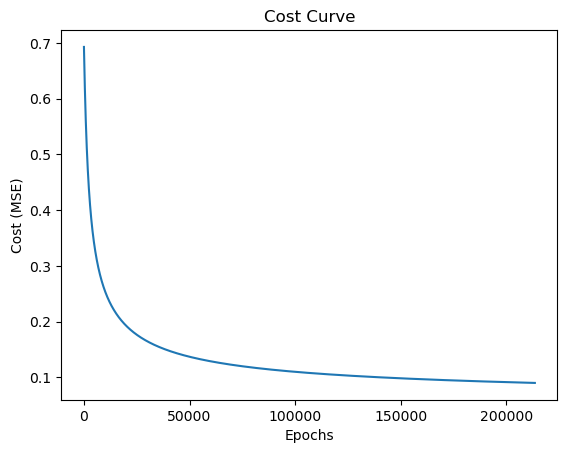

In [18]:
plt.plot(costhistory)
plt.xlabel("Epochs")
plt.ylabel("Cost (MSE)")
plt.title("Cost Curve")
plt.show()



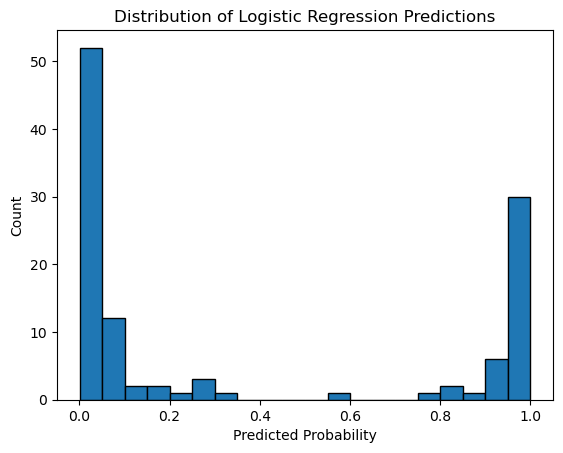

In [21]:
plt.hist(Y_predctions, bins=20, edgecolor='black')
plt.xlabel("Predicted Probability")
plt.ylabel("Count")
plt.title("Distribution of Logistic Regression Predictions")
plt.show()